# 09 - SciPy & SymPy

**Sources:** Summer School *BonusSlides* ("Introduction to SciPy and SymPy": I/O, statistics, linear algebra,
FFT, optimisation, interpolation, integration, signal & image processing, sparse matrices, profiling, SymPy)
and Bootcamp BP5 (SciPy heading).

**Modern notes (slides are from ~2013 and several things moved):**

| Slides | Today |
|---|---|
| `scipy.mean()`, `scipy.var()`... | use `np.mean`, `np.var`, ... |
| `scipy.fftpack` | `scipy.fft` (faster, same ideas) |
| `scipy.optimize.anneal` | removed -> `dual_annealing`, `differential_evolution` |
| `optimize.fmin_bfgs`, `fmin_tnc` | `optimize.minimize(method="BFGS" / "TNC")` |
| `integrate.odeint` | still works; `solve_ivp` is the modern API |
| `scipy.misc.face()/lena()` | `scipy.datasets.face()` (needs a download) - we use synthetic images |
| `scipy.stats.contingency.expected_freq` | unchanged |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy import stats, linalg, optimize, interpolate, integrate, signal, ndimage, sparse
import scipy.fft as sfft

rng = np.random.default_rng(0)
print(scipy.__version__)

1.18.1


## 1. Input / output (`scipy.io`)
Read/write MATLAB `.mat`, Matrix Market, WAV, ARFF, NetCDF...

In [2]:
import os, tempfile
from scipy import io as spio

tmpdir = tempfile.mkdtemp()
mat_path = os.path.join(tmpdir, "ex.mat")
spio.savemat(mat_path, {"mat_a": np.ones((2, 2))})
print(spio.loadmat(mat_path)["mat_a"])

from scipy.io import wavfile
fs = 8000
t = np.arange(fs) / fs
wavfile.write(os.path.join(tmpdir, "tone.wav"), fs, (0.3 * np.sin(2 * np.pi * 440 * t) * 32767).astype(np.int16))
rate, data = wavfile.read(os.path.join(tmpdir, "tone.wav"))
print(rate, data.shape, data.dtype)

[[1. 1.]
 [1. 1.]]
8000 (8000,) int16


## 2. Statistics (`scipy.stats`)
### 2.1 Descriptive statistics

In [3]:
R = stats.norm.rvs(loc=1, scale=0.5, size=1000, random_state=rng)
d = stats.describe(R)
print(d)
print(f"n={d.nobs}  min={d.minmax[0]:.3f} max={d.minmax[1]:.3f}  mean={d.mean:.3f}  var={d.variance:.3f}  "
      f"skew={d.skewness:.3f}  kurtosis={d.kurtosis:.3f}")
print(np.percentile(R, [5, 50, 95]), stats.scoreatpercentile(R, 95), stats.mode([1, 2, 2, 3]).mode, stats.moment(R, 2))

DescribeResult(nobs=np.int64(1000), minmax=(np.float64(-0.9497108650271695), np.float64(2.5330183695244486)), mean=np.float64(0.9759858616185065), variance=np.float64(0.23875033770605122), skewness=np.float64(-0.07323207437154468), kurtosis=np.float64(0.29004427542554545))
n=1000  min=-0.950 max=2.533  mean=0.976  var=0.239  skew=-0.073  kurtosis=0.290
[0.22202724 0.96258907 1.75702449] 1.757024487746357 2 0.23851158736834516


### 2.2 Probability distributions
80+ continuous (`norm, t, chi2, uniform, expon, gamma, beta, ...`) and ~10 discrete (`binom, poisson, ...`).
Two usage styles:
1. **frozen** distribution `N = stats.norm(loc, scale)`, then `N.rvs()`, `N.pdf()`, `N.cdf()`, `N.ppf()`, `N.mean()`
2. pass parameters in every call: `stats.norm.rvs(loc=2, scale=0.2, size=3)`

Methods: `rvs` (random samples), `pdf`/`pmf`, `cdf`, `sf` (1-cdf), `ppf` (inverse cdf / quantile), `fit`, `interval`.

In [4]:
N = stats.norm(loc=1, scale=0.5)
print(N.rvs(5, random_state=1))
print(N.pdf([-1, 1, 2]), N.cdf(1), N.ppf([0.025, 0.975]), N.interval(0.95), N.mean(), N.std())
print(stats.norm.pdf(1, loc=2, scale=0.2), stats.binom.pmf(3, n=10, p=0.5), stats.poisson.cdf(2, mu=2.4))

[1.81217268 0.69412179 0.73591412 0.46351569 1.43270381]
[2.67660452e-04 7.97884561e-01 1.07981933e-01] 0.5 [0.02001801 1.97998199] (np.float64(0.020018007729972975), np.float64(1.979981992270027)) 1.0 0.5
7.4335975736714894e-06 0.1171875 0.5697087466575106


fitted loc=0.060, scale=0.988


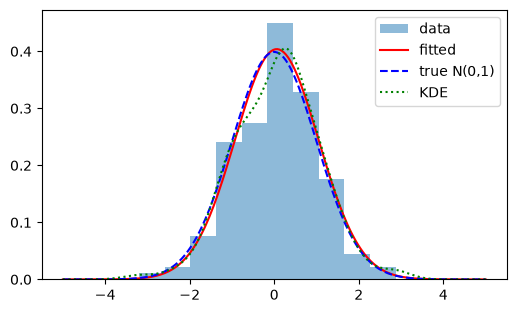

In [5]:
# Density estimation: histogram vs true pdf  /  fitting a distribution to data
data = stats.norm.rvs(loc=0, scale=1, size=150, random_state=rng)
loc_hat, scale_hat = stats.norm.fit(data)
print(f"fitted loc={loc_hat:.3f}, scale={scale_hat:.3f}")

x = np.linspace(-5, 5, 200)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(data, density=True, alpha=0.5, label="data")
ax.plot(x, stats.norm.pdf(x, loc_hat, scale_hat), "r-", label="fitted")
ax.plot(x, stats.norm.pdf(x), "b--", label="true N(0,1)")
ax.plot(x, stats.gaussian_kde(data)(x), "g:", label="KDE")
ax.legend()
plt.show()

In [6]:
# Exercise from the slides: 1000 Poisson samples, estimate the parameter (MLE of lambda = sample mean)
mu = 2.4
sample = stats.poisson.rvs(mu, size=1000, random_state=rng)
print("estimated lambda:", sample.mean())

# Multivariate normal (slides): mean (0,0), covariance [[1, .5],[.5, 1]]
xy = rng.multivariate_normal([0, 0], [[1, 0.5], [0.5, 1]], 500)
print(np.cov(xy.T).round(2), np.corrcoef(xy.T)[0, 1].round(2))

estimated lambda: 2.342
[[1.01 0.45]
 [0.45 0.9 ]] 0.47


### 2.3 Statistical tests
Always: state H0, pick a test whose assumptions hold, read the **p-value** (probability of data at least this
extreme *if H0 were true*), and report an effect size, not just "significant".

In [7]:
# Chi-square test of independence on a contingency table
obs = np.array([[10, 20, 10], [20, 20, 10]])
chi2, p, dof, expected = stats.chi2_contingency(obs)
print(f"chi2={chi2:.3f} p={p:.3f} dof={dof}")
print(expected.round(2))

# Fisher exact test (small counts): whales vs sharks in two oceans
odds, pval = stats.fisher_exact([[8, 2], [1, 5]])
print(f"odds ratio={odds:.1f}  p={pval:.4f}")

chi2=2.250 p=0.325 dof=2
[[13.33 17.78  8.89]
 [16.67 22.22 11.11]]
odds ratio=20.0  p=0.0350


In [8]:
# t-tests: independent samples and paired samples
rvs1 = stats.norm.rvs(loc=5, scale=10, size=500, random_state=rng)
rvs2 = stats.norm.rvs(loc=5, scale=10, size=500, random_state=rng)
rvs3 = stats.norm.rvs(loc=7, scale=10, size=500, random_state=rng)
print("same mean   :", stats.ttest_ind(rvs1, rvs2))
print("diff mean   :", stats.ttest_ind(rvs1, rvs3))
before = rvs1
after = rvs1 + stats.norm.rvs(loc=1, scale=3, size=500, random_state=rng)
print("paired      :", stats.ttest_rel(before, after))

# More tests (names from the slides): mannwhitneyu, spearmanr, pearsonr, f_oneway, normaltest, kruskal
print(stats.mannwhitneyu(rvs1, rvs3).pvalue, stats.pearsonr(before, after)[0].round(3), stats.spearmanr(before, after)[0].round(3))
print(stats.f_oneway(rvs1, rvs2, rvs3).pvalue, stats.normaltest(rvs1).pvalue, stats.kruskal(rvs1, rvs2, rvs3).pvalue)

same mean   : TtestResult(statistic=np.float64(-0.7180547100473273), pvalue=np.float64(0.4728916070166858), df=np.float64(998.0))
diff mean   : TtestResult(statistic=np.float64(-3.098126155679519), pvalue=np.float64(0.002001955516417832), df=np.float64(998.0))
paired      : TtestResult(statistic=np.float64(-6.6857572206232385), pvalue=np.float64(6.166969509964603e-11), df=np.int64(499))
0.0015058110988688189 0.951 0.948
0.005015229597407586 0.5363324033598238 0.004429774008127667


## 3. Linear algebra (`scipy.linalg`, also `numpy.linalg`)
`inv, pinv, solve, det, norm, eig, svd, qr, lu, cholesky, expm, logm, sinm/cosm, funm`

In [9]:
a = np.array([[3, 2, 0], [1, -1, 0], [0, 5, 1]])
b = np.array([2, 4, -1])
x = linalg.solve(a, b)
print(x, a @ x, np.allclose(a @ x, b))         # allclose: |a-b| <= atol + rtol*|b|

A = rng.standard_normal((5, 3))
B = linalg.pinv(A)                              # Moore-Penrose pseudo-inverse (least-squares inverse)
print(np.allclose(A, A @ B @ A), np.allclose(B, B @ A @ B))

Mat = np.arange(9).reshape(3, 3) + np.diag([1, 0, 1])
U, S, Vt = linalg.svd(Mat)
print(S, np.allclose(U @ np.diag(S) @ Vt, Mat))

[ 2. -2.  9.] [ 2.  4. -1.] True
True True
[14.88982544  0.45294236  0.29654967] True


In [10]:
# Least squares: fit y = c0 + c1 x   (the numerics behind regression and PCA)
xs = np.linspace(0, 10, 30)
ys = 2.5 + 0.8 * xs + rng.normal(0, 0.5, 30)
design = np.column_stack([np.ones_like(xs), xs])
coef, residuals, rank, sv = linalg.lstsq(design, ys)
print(coef.round(3), rank)

[2.738 0.772] 2


## 4. Fast Fourier Transform (`scipy.fft`)
Slides: generate a noisy signal, find its dominant frequency, filter the high frequencies, invert.

detected frequency:

 0.2 Hz; expected: 0.2


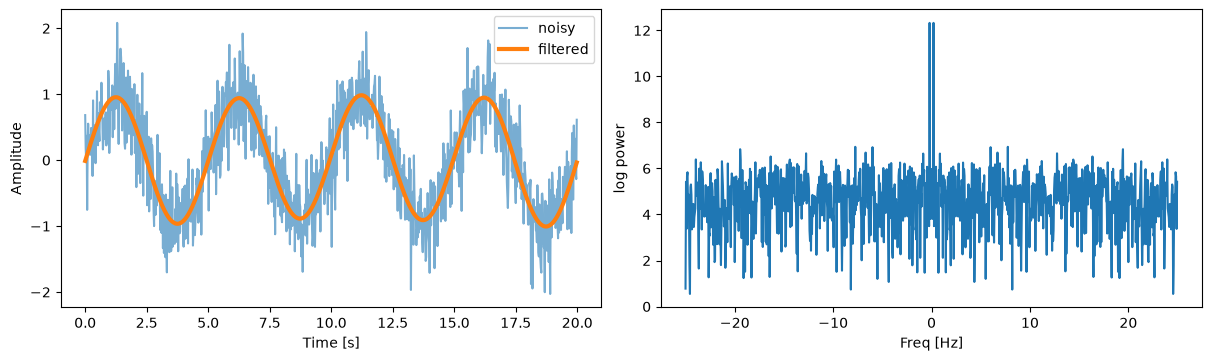

In [11]:
time_step = 0.02
period = 5.0
time_vec = np.arange(0, 20, time_step)
sig = np.sin(2 * np.pi * time_vec / period) + 0.4 * rng.standard_normal(time_vec.size)

freqs = sfft.fftfreq(sig.size, d=time_step)
sig_fft = sfft.fft(sig)
pos = freqs > 0
fpeak = freqs[pos][np.abs(sig_fft)[pos].argmax()]
print("detected frequency:", fpeak, "Hz; expected:", 1 / period)

filtered_fft = sig_fft.copy()
filtered_fft[np.abs(freqs) > fpeak] = 0           # brutal low-pass filter
main_signal = sfft.ifft(filtered_fft).real

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), constrained_layout=True)
axes[0].plot(time_vec, sig, alpha=0.6, label="noisy"); axes[0].plot(time_vec, main_signal, lw=3, label="filtered")
axes[0].set(xlabel="Time [s]", ylabel="Amplitude"); axes[0].legend()
axes[1].plot(sfft.fftshift(freqs), np.log1p(np.abs(sfft.fftshift(sig_fft)) ** 2))
axes[1].set(xlabel="Freq [Hz]", ylabel="log power")
plt.show()

**Challenge (slides):** remove periodic noise from an image with the 2-D FFT (`scipy.fft.fft2`, `fftshift`,
zero the noise peaks, `ifft2`). Below: the idea on a synthetic image; do the real one in project 05.

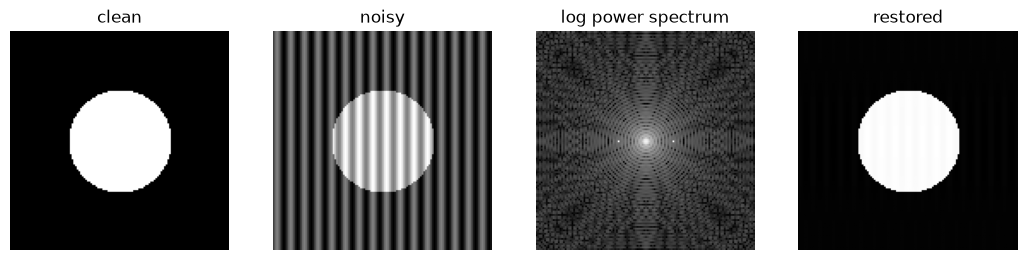

In [12]:
yy, xx = np.mgrid[0:128, 0:128]
clean_img = ((xx - 64) ** 2 + (yy - 64) ** 2 < 30 ** 2).astype(float)       # a white disk
noisy_img = clean_img + 0.5 * np.sin(2 * np.pi * xx / 8)                      # periodic stripes
F = sfft.fftshift(sfft.fft2(noisy_img))
power = np.log1p(np.abs(F))
mask = np.ones_like(F, dtype=bool)
# 128 px / 8 px per stripe = 16 cycles -> two spectral peaks at +-16 columns from the (shifted) centre (64, 64)
mask[63:66, [64 - 16, 64 + 16]] = False                                       # notch filter on the two peaks
restored = sfft.ifft2(sfft.ifftshift(F * mask)).real

fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, im, title in zip(axes, [clean_img, noisy_img, power, restored], ["clean", "noisy", "log power spectrum", "restored"]):
    ax.imshow(im, cmap="gray"); ax.set_title(title); ax.axis("off")
plt.show()

## 5. Optimisation (`scipy.optimize`)
Minimisation, root finding, curve fitting. Results **depend on the starting point** for non-convex functions.

In [13]:
def f(x):
    return x ** 2 + 10 * np.sin(x)

xg = np.arange(-10, 10, 0.1)
res_local = optimize.minimize(lambda v: f(v[0]), x0=[0.0], method="BFGS")
res_other = optimize.minimize(lambda v: f(v[0]), x0=[5.0], method="BFGS")
print("start 0 ->", res_local.x.round(4), res_local.fun.round(4))
print("start 5 ->", res_other.x.round(4), res_other.fun.round(4), "<- a LOCAL minimum, not the global one")

# global strategies: brute force grid, differential evolution, basin hopping, dual annealing
print("brute               :", optimize.brute(f, ((-10, 10, 0.1),)).round(3))
print("differential_evol   :", optimize.differential_evolution(f, [(-10, 10)], seed=1).x.round(3))
print("scalar bounded      :", optimize.minimize_scalar(f, bounds=(-10, 10), method="bounded").x.round(3))

start 0 -> [-1.3064] -7.9458
start 5 -> [3.8375] 8.3156 <- a LOCAL minimum, not the global one
brute               : [-1.306]
differential_evol   : [-1.306]
scalar bounded      : -1.306


In [14]:
# Root finding: where f(x) = 0 depends on the initial guess
print(optimize.fsolve(f, 1), optimize.fsolve(f, -2.5))
print(optimize.brentq(f, -4, -1))                   # bracketing method, guaranteed if signs differ

[0.] [-2.47948183]
-2.479481833541344


fitted a, b: [0.951 9.716] (truth 1, 10) +/- [0.051 3.627]


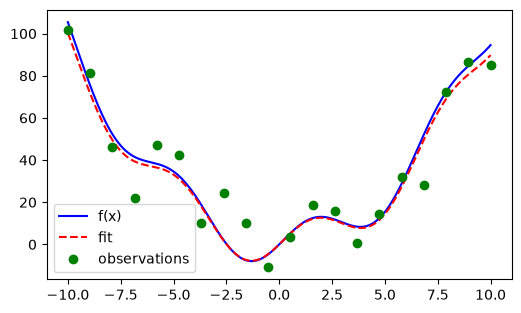

In [15]:
# Curve fitting with noisy data
x = np.linspace(-10, 10, 20)
obs = f(x) + 10 * rng.standard_normal(x.size)

def fguess(x, a, b):
    return a * x ** 2 + b * np.sin(x)

params, cov = optimize.curve_fit(fguess, x, obs, p0=[2, 2])
print("fitted a, b:", params.round(3), "(truth 1, 10) +/-", np.sqrt(np.diag(cov)).round(3))

xf = np.linspace(-10, 10, 200)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(xf, f(xf), "b-", label="f(x)"); ax.plot(xf, fguess(xf, *params), "r--", label="fit"); ax.plot(x, obs, "go", label="observations")
ax.legend(); plt.show()

In [16]:
# Constrained / multivariable:  minimise (x-1)^2 + (y-2.5)^2  s.t. x - 2y + 2 >= 0 and x,y >= 0
res = optimize.minimize(lambda v: (v[0] - 1) ** 2 + (v[1] - 2.5) ** 2, x0=[2, 0], bounds=[(0, None), (0, None)],
                        constraints=[{"type": "ineq", "fun": lambda v: v[0] - 2 * v[1] + 2}])
print(res.x.round(3), res.success)

# linear programming
lp = optimize.linprog(c=[-1, -2], A_ub=[[1, 1], [1, 3]], b_ub=[4, 6], bounds=[(0, None)] * 2)
print("max x+2y ->", lp.x, -lp.fun)

[1.4 1.7] True


max x+2y -> [3. 1.] 5.0


## 6. Interpolation (`scipy.interpolate`)
Challenge from the slides: linear vs cubic interpolation of noisy samples of a sine.

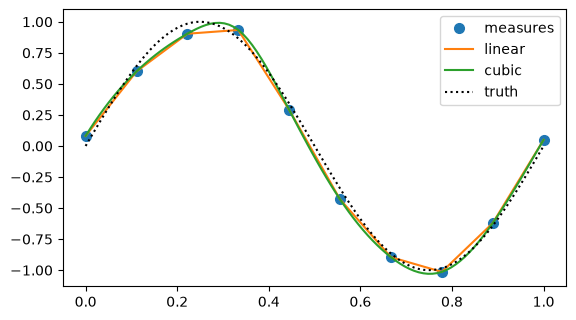

interp1d cubic == CubicSpline(not-a-knot): True


In [17]:
measured_time = np.linspace(0, 1, 10)
measures = np.sin(2 * np.pi * measured_time) + (rng.random(10) * 2 - 1) * 1e-1
computed_time = np.linspace(0, 1, 100)

linear = interpolate.interp1d(measured_time, measures)
cubic = interpolate.interp1d(measured_time, measures, kind="cubic")
spline = interpolate.CubicSpline(measured_time, measures)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(measured_time, measures, "o", ms=7, label="measures")
ax.plot(computed_time, linear(computed_time), label="linear")
ax.plot(computed_time, cubic(computed_time), label="cubic")
ax.plot(computed_time, np.sin(2 * np.pi * computed_time), "k:", label="truth")
ax.legend(); plt.show()
print("interp1d cubic == CubicSpline(not-a-knot):", np.allclose(cubic(computed_time), spline(computed_time)))

## 7. Numerical integration and ODEs (`scipy.integrate`)

In [18]:
res, err = integrate.quad(np.sin, 0, np.pi / 2)
print(res, err)
print(integrate.quad(lambda x: np.exp(-x ** 2), -np.inf, np.inf)[0], np.sqrt(np.pi))
print(integrate.dblquad(lambda y, x: x * y, 0, 1, 0, 1)[0])                  # double integral = 1/4
print(integrate.trapezoid(np.sin(xf), xf), integrate.simpson(np.sin(xf), x=xf))   # from samples

0.9999999999999999

 1.1102230246251564e-14
1.7724538509055159 1.7724538509055159
0.24999999999999997
4.440892098500626e-16 3.780976506384537e-06


**Damped oscillator** from the slides: $\ddot{x} + 2\zeta\omega_0\dot{x} + \omega_0^2 x = 0$. Rewrite as a first-order
system for $Y=(y,\dot{y})$ with $\nu = c/m$, $o = k/m$: $\dot{y}_0 = y_1$, $\dot{y}_1 = -\nu y_1 - o\,y_0$.
Damping ratio $\zeta = c / (2\sqrt{km})$: $>1$ overdamped, $=1$ critical, $<1$ underdamped, $0$ undamped.

damping ratio: 0.141 -> underdamped


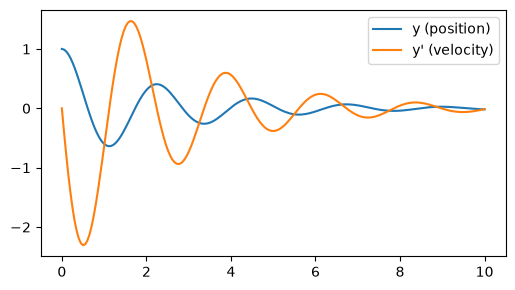

In [19]:
m_, k_, c_ = 0.5, 4, 0.4
zeta = c_ / (2 * m_ * np.sqrt(k_ / m_))
nu, o = c_ / m_, k_ / m_
print("damping ratio:", round(zeta, 3), "-> underdamped" if zeta < 1 else "")

def dy(t, y):
    return [y[1], -nu * y[1] - o * y[0]]

sol = integrate.solve_ivp(dy, (0, 10), [1, 0], t_eval=np.linspace(0, 10, 200))
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(sol.t, sol.y[0], label="y (position)"); ax.plot(sol.t, sol.y[1], label="y' (velocity)"); ax.legend(); plt.show()

## 8. Signal processing (`scipy.signal`)
Convolution, filter design (`firwin`, `butter`), filtering (`lfilter`, `filtfilt`), `detrend`, peak finding, resampling.

mean before/after: 3.52 0.0


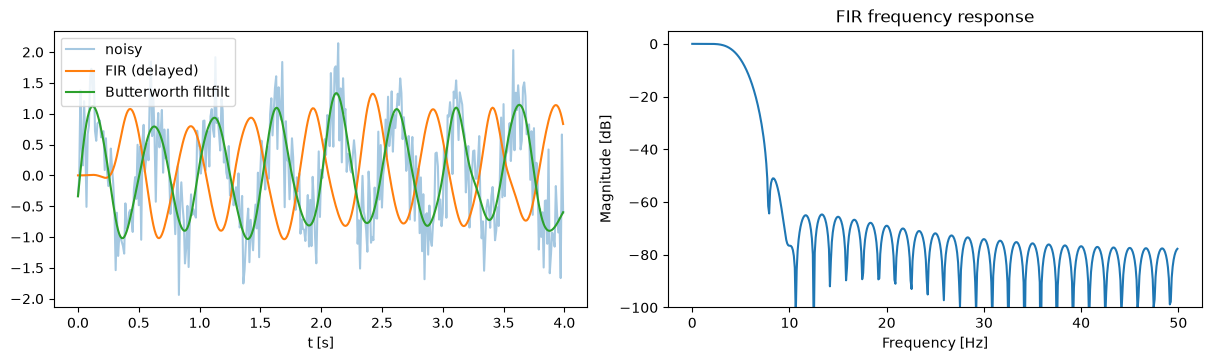

peak times: [0.12 0.63 1.12 1.63 2.12 2.62 3.11 3.63]


In [20]:
# Challenge from the slides: linear signal + noise, then detrend
tt = np.linspace(0, 10, 200)
lin = 0.7 * tt + rng.normal(0, 0.3, tt.size)
det = signal.detrend(lin)
print("mean before/after:", lin.mean().round(2), det.mean().round(6))

# Low-pass FIR (as in the slides) and a Butterworth IIR, applied to a noisy 2 Hz sine sampled at 100 Hz
fs = 100
t = np.arange(0, 4, 1 / fs)
noisy = np.sin(2 * np.pi * 2 * t) + 0.5 * rng.standard_normal(t.size)
fir = signal.firwin(61, cutoff=0.1, window="hamming")           # cutoff relative to Nyquist (fs/2 = 50 Hz) -> 5 Hz
b_iir, a_iir = signal.butter(4, 5, btype="low", fs=fs)
fir_out = signal.lfilter(fir, 1, noisy)
iir_out = signal.filtfilt(b_iir, a_iir, noisy)                   # zero-phase (forward + backward)

w, h = signal.freqz(fir, 1, fs=fs)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), constrained_layout=True)
axes[0].plot(t, noisy, alpha=0.4, label="noisy"); axes[0].plot(t, fir_out, label="FIR (delayed)"); axes[0].plot(t, iir_out, label="Butterworth filtfilt")
axes[0].legend(); axes[0].set_xlabel("t [s]")
axes[1].plot(w, 20 * np.log10(np.abs(h) + 1e-12)); axes[1].set(xlabel="Frequency [Hz]", ylabel="Magnitude [dB]", ylim=(-100, 5), title="FIR frequency response")
plt.show()

peaks, _ = signal.find_peaks(iir_out, height=0.5, distance=20)
print("peak times:", t[peaks])

## 9. Image processing (`scipy.ndimage`)
Filters, geometric transforms, measurements and morphology on N-D arrays. We build a synthetic image
(no download needed).

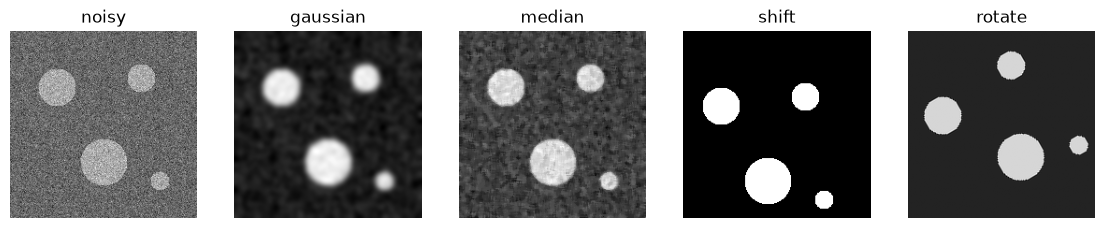

In [21]:
yy, xx = np.mgrid[0:200, 0:200]
img = np.zeros((200, 200))
for cx, cy, r in [(50, 60, 20), (140, 50, 15), (100, 140, 25), (160, 160, 10)]:
    img[(xx - cx) ** 2 + (yy - cy) ** 2 < r ** 2] = 1.0
noisy = img + 0.35 * rng.standard_normal(img.shape)

gauss = ndimage.gaussian_filter(noisy, sigma=3)
median = ndimage.median_filter(noisy, size=5)
shifted = ndimage.shift(img, (20, -10))
rotated = ndimage.rotate(img, 30, reshape=False)

fig, axes = plt.subplots(1, 5, figsize=(14, 3))
for ax, im, tt_ in zip(axes, [noisy, gauss, median, shifted, rotated], ["noisy", "gaussian", "median", "shift", "rotate"]):
    ax.imshow(im, cmap="gray"); ax.set_title(tt_); ax.axis("off")
plt.show()

In [22]:
# Measurements: label the blobs and compute their areas (slides' "SEM glass image" challenge, in miniature)
mask = median > 0.5
labels, nb = ndimage.label(mask)
areas = ndimage.sum(mask, labels, range(1, nb + 1))
centres = ndimage.center_of_mass(mask, labels, range(1, nb + 1))
print(nb, "objects; areas:", areas, "| mean area:", areas.mean().round(1))
print("filled fraction:", mask.mean().round(3), "| centres:", [(round(r), round(c)) for r, c in centres])

4 objects; areas: [ 687. 1249. 1938.  284.] | mean area: 1039.5
filled fraction: 0.104 | centres: [(50, 140), (60, 50), (140, 100), (160, 160)]


## 10. Sparse matrices (`scipy.sparse`)
A matrix that is *mostly zeros* stores only the non-zeros. A dense $n\times n$ float matrix needs $8n^2$ bytes -
for $n=10^6$ that is 8 TB!

| Format | Best for |
|---|---|
| `coo_matrix` | **constructing** from (row, col, value) triplets |
| `lil_matrix` / `dok_matrix` | incremental edits |
| `csr_matrix` | fast row slicing, matrix-vector products |
| `csc_matrix` | fast column slicing, many solvers |
| `dia_matrix` | banded / diagonal matrices |
| `bsr_matrix` | block structure |

In [23]:
# Challenge: build this matrix with coo_matrix
#   [[4 0 9 0], [0 7 0 0], [0 0 0 0], [0 0 0 5]]
row = np.array([0, 0, 1, 3])
col = np.array([0, 2, 1, 3])
val = np.array([4, 9, 7, 5])
M = sparse.coo_matrix((val, (row, col)), shape=(4, 4))
print(M.toarray(), M.nnz, M.shape)
try:
    M[0, 0]
except TypeError as err:
    print("COO cannot be indexed:", err)
print(M.tocsr()[0].toarray(), M.tocsr()[:, 2].toarray().ravel())      # convert to CSR to slice

[[4 0 9 0]
 [0 7 0 0]
 [0 0 0 0]
 [0 0 0 5]] 4 (4, 4)
COO cannot be indexed: 'coo_matrix' object is not subscriptable
[[4 0 9 0]] [9 0 0 0]


In [24]:
# Solve a sparse tridiagonal system (slides' spdiags example)
from scipy.sparse.linalg import spsolve
mtx = sparse.spdiags([[1, 2, 3, 4, 5], [6, 5, 8, 9, 10]], [0, 1], 5, 5).tocsc()
rhs = np.array([1, 2, 3, 4, 5])
xsol = spsolve(mtx, rhs)
print(mtx.toarray(), xsol, np.allclose(mtx @ xsol, rhs), sep="\n")

big = sparse.random(10_000, 10_000, density=1e-4, format="csr", random_state=0)
print(f"10000x10000 sparse: {big.data.nbytes / 1e3:.0f} kB of values vs dense {8 * 10_000 ** 2 / 1e9:.1f} GB")

# eigenvalues of large sparse matrices: scipy.sparse.linalg.eigsh / svds (ARPACK)
from scipy.sparse.linalg import eigsh
sym = (big + big.T)
print(eigsh(sym, k=3, which="LA", return_eigenvectors=False).round(3))

[[ 1  5  0  0  0]
 [ 0  2  8  0  0]
 [ 0  0  3  9  0]
 [ 0  0  0  4 10]
 [ 0  0  0  0  5]]
[106.  -21.    5.5  -1.5   1. ]
True


10000x10000 sparse: 80 kB of values vs dense 0.8 GB
[2.302 2.327 2.342]


## 11. Special functions (`scipy.special`)
Gamma, Bessel, elliptic, error functions, Legendre, hypergeometric... plus the numerically stable helpers
`logsumexp`, `expit` (sigmoid), `comb`, `erf`.

In [25]:
from scipy import special
print(special.gamma(5), special.gammaln(100).round(2), special.erf(1).round(4), special.jv(0, 2.4).round(4),
      special.comb(10, 3), special.expit([-2, 0, 2]).round(3), special.logsumexp([1000, 1000]))

24.0 359.13 0.8427 0.0025 120.0 [0.119 0.5   0.881] 1000.6931471805599


## 12. SymPy - symbolic mathematics
A pure-Python computer algebra system (think Mathematica/Maple-lite): exact arithmetic, algebra, calculus,
equation solving, matrices. Symbols must be **declared**.

In [26]:
import sympy as sp
sp.init_printing(use_unicode=True)

r = sp.Rational(1, 2)
print(r, r.evalf(), sp.Rational(1, 2) + sp.Rational(2, 3), sp.sqrt(2 * sp.pi / 3).evalf(30))
print(sp.pi.evalf(40), sp.oo > 10000, sp.oo + 10000, sp.E ** sp.I * 1, sp.exp(sp.I * sp.pi))

1/2 0.500000000000000 7/6 1.44720250911653531872602925458
3.141592653589793238462643383279502884197 True oo exp(I) -1


In [27]:
x, y = sp.symbols("x y")
print(x - y + x - y - x + y + y)                    # -> x   (automatic simplification of trivial terms)
print(sp.expand((x + y) ** 2), sp.expand((x + x * y) ** 3))
print(sp.expand(sp.cos(x + y), trig=True))
print(sp.simplify((x + x * y) / x), sp.simplify(sp.sin(x) / sp.cos(x)), sp.trigsimp(sp.sin(x) ** 2 + sp.cos(x) ** 2))
print(sp.factor(x ** 4 - 3 * x ** 2 + 1), sp.factor(x ** 2 - 1), sp.together(1 / x + 1 / y), sp.apart(1 / (x * (x + 1))))

x
x**2 + 2*x*y + y**2 x**3*y**3 + 3*x**3*y**2 + 3*x**3*y + x**3
-sin(x)*sin(y) + cos(x)*cos(y)


y + 1 tan(x) 1
(x**2 - x - 1)*(x**2 + x - 1) (x - 1)*(x + 1) (x + y)/(x*y) -1/(x + 1) + 1/x


In [28]:
# Calculus: limits, derivatives, Taylor series, integrals
print(sp.limit(sp.sin(x) / x, x, 0), sp.limit(1 / x, x, sp.oo), sp.limit(x ** x, x, 0), sp.limit((1 + 1 / x) ** x, x, sp.oo))
print(sp.diff(sp.sin(2 * x), x), sp.diff(sp.tan(x), x), sp.diff(sp.sin(2 * x), x, 3), sp.diff(x ** 2 * y ** 3, x, y))
print(sp.series(sp.cos(x), x, 0, 8))
print(sp.integrate(2 * x ** 4, x), sp.integrate(sp.cos(x), x), sp.integrate(sp.log(x) * x, x), sp.integrate(sp.log(x) * x, (x, 0, 1)))
print(sp.integrate(sp.exp(-x ** 2), (x, -sp.oo, sp.oo)))

1 0 1 E
2*cos(2*x) tan(x)**2 + 1 -8*cos(2*x) 6*x*y**2
1 - x**2/2 + x**4/24 - x**6/720 + O(x**8)


2*x**5/5 sin(x) x**2*log(x)/2 - x**2/4 -1/4
sqrt(pi)


In [29]:
# Equations
print(sp.solve(x ** 4 - 1, x))
print(sp.solve([x + 5 * y - 2, -3 * x + 6 * y - 15], [x, y]))
print(sp.solve(sp.exp(x) + 1, x))
print(sp.solve([x + y - 2, 2 * x + y], [x, y]))      # slide challenge -> {x: -2, y: 4}

# Matrices
A = sp.Matrix([[1, x], [y, 1]])
print(A.det(), A ** 2, A.inv(), A.subs({x: 2, y: 3}), sp.Matrix([[2, 1], [1, 2]]).eigenvals(), sep="\n")

# Differential equations:  f'' + 9 f = 0
f = sp.Function("f")
ode = sp.Eq(f(x).diff(x, 2) + 9 * f(x), 0)
print(sp.dsolve(ode, f(x)))

[-1, 1, -I, I]
{x: -3, y: 1}
[I*pi]
{x: -2, y: 4}
-x*y + 1
Matrix([[x*y + 1, 2*x], [2*y, x*y + 1]])
Matrix([[-1/(x*y - 1), x/(x*y - 1)], [y/(x*y - 1), -1/(x*y - 1)]])
Matrix([[1, 2], [3, 1]])
{3: 1, 1: 1}
Eq(f(x), C1*sin(3*x) + C2*cos(3*x))


In [30]:
# From symbols to fast numerics: lambdify turns an expression into a NumPy function
expr = sp.sin(x) * sp.exp(-x / 5)
fn = sp.lambdify(x, expr, "numpy")
print(fn(np.linspace(0, 10, 5)).round(3), sp.latex(sp.diff(expr, x)))

[ 0.     0.363 -0.353  0.209 -0.074] - \frac{e^{- \frac{x}{5}} \sin{\left(x \right)}}{5} + e^{- \frac{x}{5}} \cos{\left(x \right)}


## 13. Code profiling & speed-ups from the bonus slides
Covered with runnable examples in notebook 11 (timeit, cProfile, line_profiler, vectorisation, memory order).
Sparse matrices (above) are the "storage scheme" answer when data are mostly zeros.

## Exercises

**A. Hypothesis testing drill.** Simulate two groups (n=40) with true mean difference 0.5 sd. Run `ttest_ind`
2 000 times with different seeds; what fraction rejects H0 at 5 % (the **power**)? Plot the p-value histogram
when H0 is true (it should be flat).

**B. Parameter recovery.** Simulate $y = a\,e^{-bt} + \text{noise}$, recover $(a,b)$ with `curve_fit` and give
95 % confidence intervals from the covariance matrix. Repeat 200 times and check the coverage.

**C. Denoise audio.** Create a 1-s chirp (`signal.chirp`) with white noise, design a band-pass `butter` filter,
compare spectrograms (`signal.spectrogram`) before/after.

**D. Symbolic -> numeric.** With SymPy find the stationary points of $f(x)=x^3-3x$, classify them using the second
derivative, then `lambdify` and plot.

**E. Image challenge (slides).** Segment an image into 3 phases by thresholds read off the histogram, colour them,
and estimate the mean bubble size with `ndimage.label`.

In [31]:
import shutil; shutil.rmtree(tmpdir, ignore_errors=True)

In [32]:
# Your turn